# Department buckets audit

Two charts and small tables show the size and contents of each bucket.
All counts are **payroll records**, not unique people. This notebook reads the
current retained UC/CSU files.

Graphs were coded with AI assistance


In [36]:
import polars as pl
import duckdb
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from textwrap import fill

csu = pl.read_parquet('../data/processed/golden_csu_2013-2024.parquet')
uc = pl.read_parquet('../data/processed/golden_uc_2013-2024.parquet')
combined = pl.concat([uc, csu], how='diagonal_relaxed')
duckdb.sql('CREATE OR REPLACE TEMP TABLE faculty_salaries AS SELECT * FROM combined')
pl.Config.set_tbl_rows(20)
pl.Config.set_fmt_str_lengths(48)
_ = pl.Config.set_tbl_width_chars(125)


## How large is each bucket?

Department counts combine capitalization and surrounding spaces in **nonblank
original names**. 

Other spelling difference remain separate.


In [37]:
source_counts = pl.DataFrame({
    'File': ['UC', 'CSU', 'Total'],
    'Payroll rows': [uc.height, csu.height, combined.height],
})
display(source_counts)

bucket_counts = duckdb.sql("""
    SELECT department AS bucket, COUNT(*) AS payroll_rows,
           ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM faculty_salaries), 1) AS percent,
           COUNT(DISTINCT NULLIF(LOWER(TRIM(original_department)), '')) AS department_names,
           COUNT(DISTINCT campus) AS campuses
    FROM faculty_salaries
    GROUP BY department
    ORDER BY payroll_rows DESC
""").pl()
display(bucket_counts)


File,Payroll rows
str,i64
"""UC""",270588
"""CSU""",154532
"""Total""",425120


bucket,payroll_rows,percent,department_names,campuses
str,i64,f64,i64,i64
"""Humanities & Languages""",86697,20.4,417,31
"""Other""",84032,19.8,1010,34
"""Science & Mathematics""",64167,15.1,271,32
"""Social Sciences & Communication""",54278,12.8,276,33
"""Business, Economics & Finance""",31877,7.5,97,31
"""Computer Science""",30590,7.2,73,30
"""Engineering""",29971,7.1,161,29
"""Education""",20294,4.8,117,32
"""Public Administration & Law""",11669,2.7,32,17


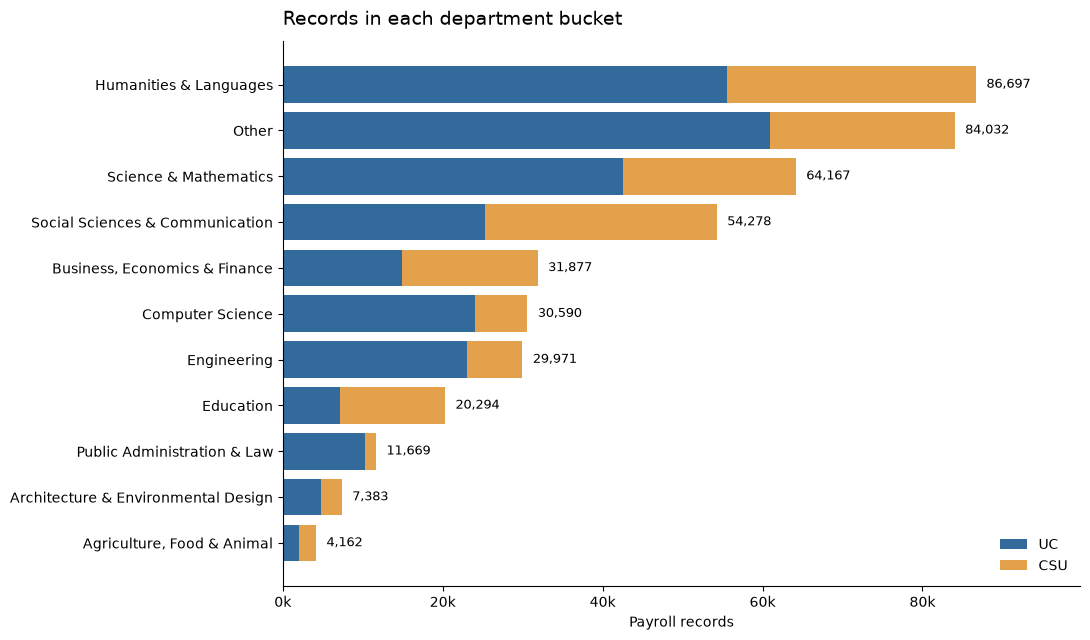

In [ ]:
# Prompt was "use matplotlib graphs to show the shape of each bucket"

# Bucket size, with UC and CSU contributions.
buckets = bucket_counts['bucket'].to_list()
uc_counts = dict(uc.group_by('department').len().iter_rows())
csu_counts = dict(csu.group_by('department').len().iter_rows())
uc_values = [uc_counts.get(bucket, 0) for bucket in buckets]
csu_values = [csu_counts.get(bucket, 0) for bucket in buckets]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(buckets, uc_values, label='UC', color='#326b9b')
ax.barh(buckets, csu_values, left=uc_values, label='CSU', color='#e3a14b')
ax.invert_yaxis()
for i, total in enumerate(bucket_counts['payroll_rows']):
    ax.text(total + max(bucket_counts['payroll_rows']) * 0.015, i,
            f'{total:,}', va='center', fontsize=9)
ax.set_xlim(0, max(bucket_counts['payroll_rows']) * 1.15)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value / 1000:.0f}k'))
ax.set_xlabel('Payroll records')
ax.set_title('Records in each department bucket', loc='left', fontsize=14, pad=12)
ax.legend(frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()


## What is inside each bucket?

Each panel shows its four largest department names, combining capitalization and
surrounding spaces for display only. Panels have different
scales; use the labels for counts. These show the largest contributors, not every
department or proof that all assignments are correct.


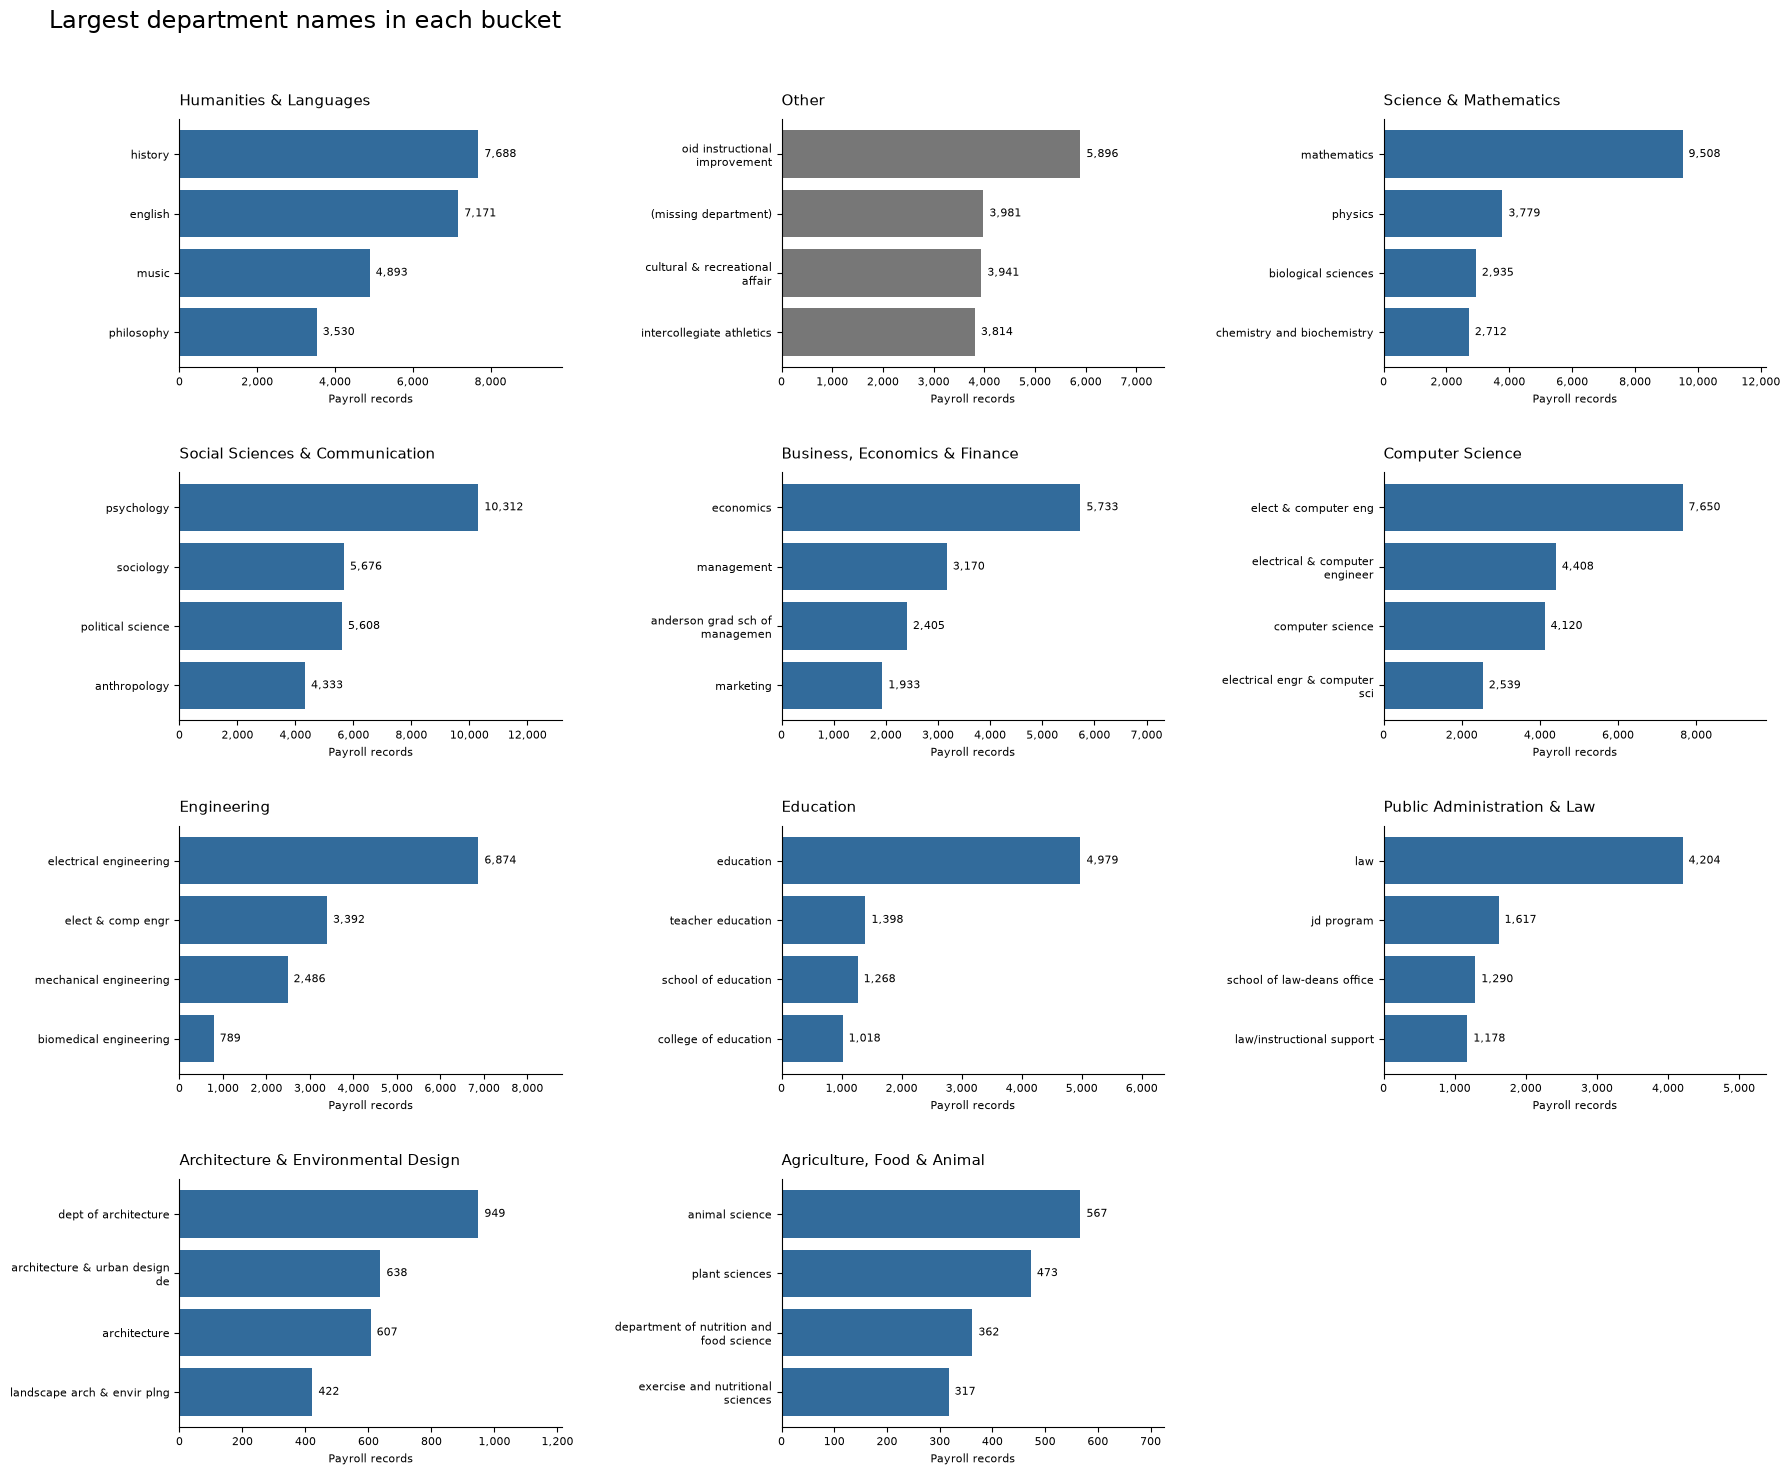

In [39]:
department_counts = duckdb.sql("""
    SELECT department AS bucket,
           COALESCE(NULLIF(LOWER(TRIM(original_department)), ''), '(missing department)') AS original_name,
           COUNT(*) AS payroll_rows
    FROM faculty_salaries
    GROUP BY ALL
    ORDER BY payroll_rows DESC, original_name
""").pl()

fig, axes = plt.subplots(4, 3, figsize=(18, 15))
for ax, bucket in zip(axes.flat, buckets):
    top = department_counts.filter(pl.col('bucket') == bucket).head(4)
    labels = [fill(name, 27) for name in top['original_name']]
    values = top['payroll_rows'].to_list()
    ax.barh(labels, values, color='#777777' if bucket == 'Other' else '#326b9b')
    ax.invert_yaxis()
    ax.set_xlim(0, max(values) * 1.28)
    for i, value in enumerate(values):
        ax.text(value + max(values) * 0.02, i, f'{value:,}', va='center', fontsize=8)
    ax.set_title(fill(bucket, 36), loc='left', fontsize=11, pad=10)
    ax.set_xlabel('Payroll records', fontsize=8)
    ax.tick_params(axis='both', labelsize=8)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f'{value:,.0f}'))
    ax.spines[['top', 'right']].set_visible(False)
for ax in axes.flat[len(buckets):]:
    ax.set_visible(False)
fig.suptitle('Largest department names in each bucket', fontsize=17, x=0.03, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.96), h_pad=3, w_pad=3)
plt.show()


In [40]:

duplicate_rows = duckdb.sql("""
    SELECT (SELECT COUNT(*) FROM faculty_salaries) -
           (SELECT COUNT(*) FROM (SELECT DISTINCT * FROM faculty_salaries))
""").fetchone()[0]

print("Duplicates :", end=" ")
print(duplicate_rows)

Duplicates : 4821


In [ ]:
# This check was reccomended by GPT - 5.6 Luna

remaining_review = duckdb.sql("""
    SELECT original_department AS department_name, department AS current_bucket,
           COUNT(*) AS payroll_rows
    FROM faculty_salaries
    WHERE (department = 'Other' AND original_department IN (
        'Social Work', 'Social Work, School of', 'Geological Sciences',
        'Department of Curriculum & Instruction', 'Index.Php'
    ))
       OR (department = 'Science & Mathematics' AND original_department IN (
        'med svs kalx radio station', 'San Diego State University',
        'Real Estate, Land Use, and Quantitative Methods'
    ))
       OR (department = 'Engineering' AND original_department = 'civil justice clinic')
    GROUP BY ALL
    ORDER BY payroll_rows DESC
""").pl()
display(remaining_review)

other_rows = combined.filter(pl.col('department') == 'Other').height
distinct_rows = combined.height - duplicate_rows
print(f"Final retained count: {combined.height:,} payroll rows across {bucket_counts.height} buckets.")
print(f"UC: {uc.height:,}; CSU: {csu.height:,}; distinct full rows: {distinct_rows:,}.")
print(f"Other: {other_rows:,} rows ({100 * other_rows / combined.height:.1f}%).")

department_name,current_bucket,payroll_rows
str,str,i64
"""Social Work""","""Other""",2177
"""Index.Php""","""Other""",1717
"""Geological Sciences""","""Other""",487
"""Social Work, School of""","""Other""",326
"""Department of Curriculum & Instruction""","""Other""",170
"""med svs kalx radio station""","""Science & Mathematics""",53
"""San Diego State University""","""Science & Mathematics""",33
"""Real Estate, Land Use, and Quantitative Methods""","""Science & Mathematics""",23
"""civil justice clinic""","""Engineering""",7


Final retained count: 425,120 payroll rows across 11 buckets.
UC: 270,588; CSU: 154,532; distinct full rows: 420,299.
Other: 84,032 rows (19.8%).
